In [11]:
import os
mactex_path = "/Library/TeX/texbin"
if mactex_path not in os.environ["PATH"]:
    os.environ["PATH"] += os.pathsep + mactex_path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pde import PDE, FieldCollection, MemoryStorage, PolarSymGrid, ScalarField
import pandas as pd
# Enable full LaTeX rendering


plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif"
})
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [16]:
def merge_presets(presets, defaults):
    """Merge each preset dict with defaults; preset values take priority."""
    return {name: {**defaults, **preset} for name, preset in presets.items()}

integration_dict = {
    'outer_radius': 60,
    'num_pts_radius': 1000,
    't_max': 100,
    'dt': .001,
}
seed_dict = {
    'N_init': 50,
    'seed_radius': 5,
    'gaussian_sharpness': 3,
    'wave_cutoff': .01,
    'init_method': 'cosine_taper'
}
analysis_dict = {
    'wavefront_method':'area',
    'wavefront_cutoff':.1,
    'tracker_time':.2,
}
default_config = {
    'r': 0.5,
    'K': 40,
    'D': 0.35,
    'a': 0.03,
    'm0': 0.25,
    'h': 0.05,
    'b_r': 0.015,
    'b_k': 0.015,
    'escape': 0.5,
    'E_r0': 0.05,
    'E_k0': 0.05,
}
preset_dicts = {
    'baseline': {
        'description': 'default config'
    },
    # 'indolent_tumor': {
    #     'description': 'Slow growth, low motility, strong immune pressure. Bounded core that barely expands.',
    #     'r':.13,
    #     'D':.13,
    #     'h':.04,
    #     'b_r':.01,
    #     'b_k':.01,
    # },
    'high motility + weak niche': {
    'description': 'High growth and high motility. Rapid front propagation with weak immune containment.',
    'r':.95,
    'D':.9,
    'h':.1,
    'b_r':.005,
    'b_k':.005,
    'escape':.75,
},
'high predation/immune pressure':
{
    'description':'Strong immune attack, low escape. The lesion struggles to establish and may regress.',
    'm0':.4,
    'a':.2,
    'h':.02,
    'b_r':.01,
    'b_k':.01,
    'escape':.1,
},
'strong niche construction':
{
    'description':'Strong ecological engineering. Niche construction quickly suppresses immune pressure and lifts carrying capacity.',
    'r':.13,
    'D':.15,
    'h':.04,
    'b_r':.05,
    'b_k':.05,
}
}
bcs = {"derivative":0}
merged_presets = merge_presets(preset_dicts, default_config)
config_dict = {'integration': integration_dict, 'seed':seed_dict,'bcs':bcs,'presets': merged_presets, 'analysis':analysis_dict}

def rolling_area(u_init, r_coords):
    """Cumulative area (polar coordinates) of u_init up to each radius."""
    dr = np.gradient(r_coords)
    return np.cumsum(2 * np.pi * r_coords * u_init * dr)

def compute_wavefront_idx_by_height(u_curr, r_coords, cutoff):
    cutoff_idx = np.flatnonzero(u_curr <= cutoff * np.max(u_curr))
    if cutoff_idx.size:
        return cutoff_idx[0]
    return -1

def compute_wavefront_idx_by_grad(u_curr):
    du = np.gradient(u_curr)
    cutoff_idx = np.argmin(du)
    if cutoff_idx.size:
        return cutoff_idx[0]
    return -1

def compute_wavefront_idx_by_area(u_curr, r_coords, cutoff):
    roll = rolling_area(u_curr, r_coords)
    total = roll[-1]
    cutoff_idx = np.flatnonzero(roll > (1-cutoff )* total)
    if cutoff_idx.size:
        return cutoff_idx[0]
    return -1

def compute_wavefront_idx(config,u_curr, r_coords):
    method_dispatch = {'height':compute_wavefront_idx_by_height, 'area':compute_wavefront_idx_by_area}
    chosen_method =method_dispatch.get(config['wavefront_method'])
    return chosen_method(u_curr, r_coords, config['wavefront_cutoff'])

def compute_participation_area(u_curr):
    total_mass = u_curr.integral
    squared_mass = (u_curr**2).integral
    effective_area = (total_mass**2) / squared_mass
    return effective_area


def build_initial_N(config):
    seed_params = config['seed']
    integration_params= config['integration']
    grid = PolarSymGrid(radius=integration_params['outer_radius'], shape = integration_params['num_pts_radius'])
    r_coords = grid.axes_coords[0]

    def super_gaussian():
        exponent = 2*seed_params['gaussian_sharpness']
        u_init = np.exp(-(r_coords/seed_params['seed_radius'])**exponent)
        cutoff_idx = compute_wavefront_idx_by_height(u_init,seed_params['wave_cutoff'])
        u_init[cutoff_idx + 1:] = 0
        return u_init

    def cosine_taper():
        u_init = 1 - (r_coords/seed_params['seed_radius'])
        u_init[u_init < 0] = 0
        return u_init

    # dispatch
    method_dispatch = {'super_gaussian':super_gaussian,'cosine_taper':cosine_taper}
    chosen_method = method_dispatch.get(seed_params['init_method'])
    u_init = chosen_method()
    total = rolling_area(u_init, r_coords)[-1]
    if total == 0:
        raise ValueError("The initial distribution is zero after applying the cutoff.")
    u_init *= seed_params['N_init'] / total
    u_field = ScalarField(grid, data=u_init, label="N")
    return u_field, r_coords

def compute_phase_quantities(params):
    baseline_growth = params['r']*params['E_r0']
    m_eff = params['m0']/(1+params['escape']*((params['E_r0']+params['E_k0'])/2))
    gamma_0 = baseline_growth - (m_eff*params['a'])
    da = params['b_r'] * params['K']/np.abs(gamma_0)
    escape_crit_num = 4*(params['a']**2)*params['h']*params['m0'] * params['K']
    escape_crit_den = params['r']*((1+ params['a']*params['h']*params['K'])**2)
    escape_crit = (escape_crit_num/escape_crit_den)-1
    return gamma_0, da, escape_crit



In [17]:
scenario_wavefront_speed = []
scenario_final_profiles = []
for preset_name, preset_config in config_dict['presets'].items():
    print(f"Running simulation for preset: {preset_name}")
    u_field, r_coords = build_initial_N(config_dict)
    Er_init = np.ones_like(u_field.data) * preset_config['E_r0']
    Ek_init = np.ones_like(u_field.data) * preset_config['E_k0']
    Er_field = ScalarField(u_field.grid, data=Er_init, label="E_r")
    Ek_field = ScalarField(u_field.grid, data=Ek_init, label="E_k")
    state = FieldCollection([u_field, Er_field, Ek_field])
    print(preset_config)
    gamma_0, da, escape_crit = compute_phase_quantities(preset_config)
    print(gamma_0, da, escape_crit)
    diff = preset_config['D']
    r = preset_config['r']
    kappa = preset_config['K']
    m_0 = preset_config['m0']
    escape = preset_config['escape']
    h = preset_config['h']
    a = preset_config['a']
    b_r = preset_config['b_r']
    b_k = preset_config['b_k']
    diffusion = f"{diff} * laplace(N)"
    logistic = f"+ {r} * E_r * N * (1 - (N / (E_k * {kappa})))"
    m_eff = f"({m_0} / (1 + {escape} * ((E_r + E_k)/2)))"
    predation = f"- {m_eff} * {a} * N / (1 + {h} * {a} * N)"
    equations = {
        "N": diffusion + logistic + predation,
        "E_r": f"(1 - E_r) * (1 - exp(- {b_r} * N))",
        "E_k": f"(1 - E_k) * (1 - exp(- {b_k} * N))",
    }
    pde_system = PDE(equations, bc=config_dict['bcs'])
    storage = MemoryStorage()
    pde_system.solve(state, t_range=config_dict['integration']['t_max'],dt=config_dict['integration']['dt'], 
                     tracker=storage.tracker(.2), adaptive = True, )
    for t_idx, time in enumerate(storage.times):
        curr_u = storage[t_idx][0].data
        analysis_dict = config_dict['analysis']
        idx = compute_wavefront_idx(analysis_dict, curr_u, r_coords)
        wavefront_r = r_coords[idx]
        scenario_wavefront_speed.append((preset_name,time,wavefront_r, rolling_area(curr_u, r_coords)[-1], compute_participation_area(storage[t_idx][0])))
    final_collection = storage[-1]
    final_Er = final_collection[1].data
    final_Ek = final_collection[2].data
    final_N = final_collection[0].data/(kappa*final_Ek)
    scenario_final_profiles.append((preset_name, final_N, final_Er))
    """
    show initial distribution
    turn into set of four plots
    show the wavefront top right
    show perc of initial population
    change labels
    set colors at the top
    use latex
    """

Running simulation for preset: baseline
{'r': 0.5, 'K': 40, 'D': 0.35, 'a': 0.03, 'm0': 0.25, 'h': 0.05, 'b_r': 0.015, 'b_k': 0.015, 'escape': 0.5, 'E_r0': 0.05, 'E_k0': 0.05, 'description': 'default config'}
0.017682926829268295 33.93103448275862 -0.9967960128159488
Running simulation for preset: high motility + weak niche
{'r': 0.95, 'K': 40, 'D': 0.9, 'a': 0.03, 'm0': 0.25, 'h': 0.1, 'b_r': 0.005, 'b_k': 0.005, 'escape': 0.75, 'E_r0': 0.05, 'E_k0': 0.05, 'description': 'High growth and high motility. Rapid front propagation with weak immune containment.'}
0.0402710843373494 4.966342557965595 -0.9969790547798066
Running simulation for preset: high predation/immune pressure
{'r': 0.5, 'K': 40, 'D': 0.35, 'a': 0.2, 'm0': 0.4, 'h': 0.02, 'b_r': 0.01, 'b_k': 0.01, 'escape': 0.1, 'E_r0': 0.05, 'E_k0': 0.05, 'description': 'Strong immune attack, low escape. The lesion struggles to establish and may regress.'}
-0.05460199004975127 7.325740318906603 -0.9239001189060642
Running simulation for

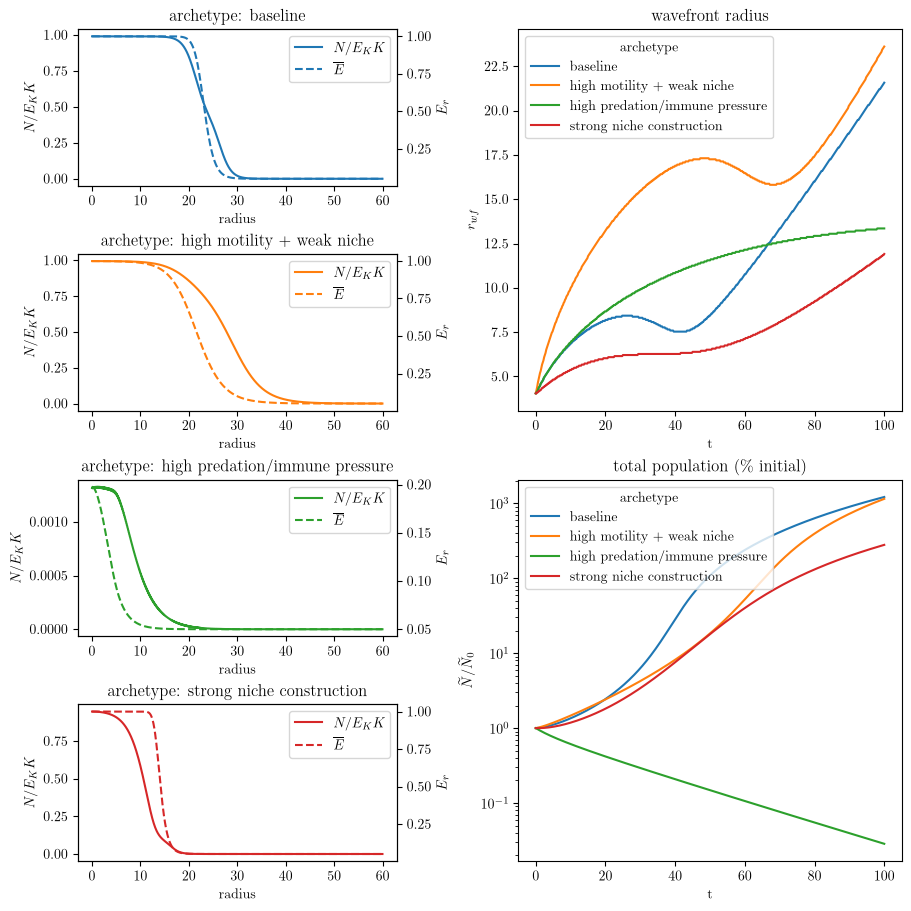

In [18]:
df = pd.DataFrame(scenario_wavefront_speed, columns = ['archetype','t','r','N','eff_area'])
df['N_init'] = config_dict['seed']['N_init']
df['N_perc'] = df['N']/df['N_init']
fig = plt.figure(figsize=(9, 9), constrained_layout=True)
gs = fig.add_gridspec(4, 2, width_ratios=[1, 1.2])
scenarios = [s for s, _, _ in scenario_final_profiles]
colors = sns.color_palette("tab10", n_colors=len(scenarios))
palette = dict(zip(scenarios, colors))
for i, (scenario, final_N, final_Er) in enumerate(scenario_final_profiles):
    ax = fig.add_subplot(gs[i, 0])
    ax_right = ax.twinx()

    line_n, = ax.plot(r_coords, final_N, color=palette[scenario], label="$N$")
    line_er, = ax_right.plot(
        r_coords, final_Er, color=palette[scenario], linestyle="--", label=r"$\bar{E}_{r}$"
    )

    ax.set_title("archetype: "+scenario)
    ax.set_xlabel("radius")
    ax.set_ylabel("$N/E_{K}K$")
    ax_right.set_ylabel(r"$E_{r}$")
    ax.legend([line_n, line_er], ["$N/E_{K}K$", r"$\overline{E}$"], loc="upper right")

ax_wavefront = fig.add_subplot(gs[:2, 1])
sns.lineplot(data=df, x="t", y="r", hue="archetype", ax=ax_wavefront)
ax_wavefront.set_title("wavefront radius")
ax_wavefront.set_ylabel("$r_{wf}$")

ax_population = fig.add_subplot(gs[2:, 1])
sns.lineplot(data=df, x="t", y="N_perc", hue="archetype", ax=ax_population)
ax_population.set_title(r"total population (\% initial)")
ax_population.set_ylabel("$\\widetilde{N} / \\widetilde{N}_{0}$")
ax_population.set_yscale("log")

plt.show()


# Trait-modified PDE (Fitness Gradient formalism)
In this section, use the same config_dict structure as above and implement the trait-modified PDE. Compare the leading order correction to the second-order corrections. Apply only to the "baseline" config


In [19]:
# Trait-coupled right-hand sides as py-pde f-strings.
# Derivation: trait-coupled PDE note (not in this repo), Sections 5 and 7 (Wickman et al. 2017, Appendix C,
# extended to trait-dependent motility). Traits z0, z1, z2 map to D = D0*L(z0), E_r = Er0*L(z1),
# E_K = EK0*L(z2), with L the logistic sigmoid of steepness k_j. Escape uses the rational law
# m_eff = m0/(1 + eps*Ebar), Ebar = (E_r + E_K)/2, as in the cells above.
#   second_order=False: leading-order system (Section 5.4)
#   second_order=True : full system with the second-order expectation corrections (Section 5.3)
#   escape_public     : omega in [0, 1], public share of the escape benefit (Section 2.2)

def logistic_derivs(z, k):
    """Return f-strings for L, L', ..., L^(5) of L(u) = 1/(1+exp(-k u)) at u = z."""
    L = f"(1/(1 + exp(-{k}*{z})))"
    s = f"({L}*(1 - {L}))"
    return (
        L,
        f"({k}*{s})",
        f"({k}**2*{s}*(1 - 2*{L}))",
        f"({k}**3*{s}*(1 - 6*{s}))",
        f"({k}**4*{s}*(1 - 2*{L})*(1 - 12*{s}))",
        f"({k}**5*{s}*(1 - 30*{s} + 120*{s}**2))",
    )


def build_rhs(
    *,
    r, K, a, h, m0, eps,           # ecology (eps = escape); m_eff = m0/(1 + eps*Ebar)
    D0, Er0, EK0,                  # coefficient scales
    k0, k1, k2,                    # sigmoid steepness per trait axis
    V0, V1, V2,                    # standing trait variances (diagonal)
    N_eps=1e-6,                    # regulariser for 1/N in trait equations
    second_order=True,             # True: full system (Section 5.3); False: leading order (Section 5.4)
    escape_public=0.0,             # omega in [0, 1]: 0 = private escape, 1 = public good (Section 2.2)
):
    if not 0.0 <= escape_public <= 1.0:
        raise ValueError("escape_public must lie in [0, 1]")
    w = 1.0 - escape_public                                  # private share of the escape index

    L0, L0p, L0pp, L0ppp, L0pppp, L0ppppp = logistic_derivs("z0", k0)
    L1, L1p, L1pp, L1ppp, _, _ = logistic_derivs("z1", k1)
    L2, L2p, L2pp, L2ppp, _, _ = logistic_derivs("z2", k2)

    # coefficient fields and their trait derivatives
    D, Dp, Dpp, Dppp, Dpppp, Dppppp = (f"({D0}*{x})" for x in (L0, L0p, L0pp, L0ppp, L0pppp, L0ppppp))
    Er, Erp, Erpp, Erppp = (f"({Er0}*{x})" for x in (L1, L1p, L1pp, L1ppp))
    EK, EKp, EKpp, EKppp = (f"({EK0}*{x})" for x in (L2, L2p, L2pp, L2ppp))

    # rational escape law and its Ebar derivatives, at Ebar(z)
    H = f"({a}/(1 + {a}*{h}*N))"
    Ebar = f"(0.5*({Er} + {EK}))"
    q = f"(1 + {eps}*{Ebar})"
    meff = f"({m0}/{q})"
    eta = f"({m0}*{eps}*{H}/(2*{q}**2))"                     # -0.5 m_E H
    kap = f"({m0}*{eps}**2*{H}/(2*{q}**3))"                  # 0.25 m_EE H
    lam = f"(-3*{m0}*{eps}**3*{H}/(4*{q}**4))"               # 0.125 m_EEE H

    # psi = -1/E_K and its chi2 derivatives
    psi1 = f"({EKp}/{EK}**2)"
    psi2 = f"({EKpp}/{EK}**2 - 2*{EKp}**2/{EK}**3)"
    psi3 = f"({EKppp}/{EK}**2 - 6*{EKp}*{EKpp}/{EK}**3 + 6*{EKp}**3/{EK}**4)"

    # per-capita fitness and selection gradients (Section 5.1)
    crowd = f"(1 - N/({K}*{EK}))"
    g = f"({r}*{Er}*{crowd} - {meff}*{H})"
    g1 = f"({Erp}*({r}*{crowd} + {w}*{eta}))"
    g2 = f"({EKp}*({r}*{Er}*N/({K}*{EK}**2) + {w}*{eta}))"

    invN = f"(1/(N + {N_eps}))"
    gN = "gradient(N)"

    if not second_order:
        # leading-order system (Section 5.4)
        rhs_N = f"{D}*laplace(N) + N*{g}"

        def transport(zi):
            return f"{D}*(laplace({zi}) + 2*dot({gN}, gradient({zi}))*{invN})"

        sorting = f"{V0}*{Dp}*laplace(N)*{invN}"
        sel1, sel2 = g1, g2
    else:
        # mean motility Dbar = <D> and its z0 derivatives (Section 5.3)
        Db = f"({D} + 0.5*{V0}*{Dpp})"
        Dbp = f"({Dp} + 0.5*{V0}*{Dppp})"                    # also <D'>, the sorting coefficient
        Dbpp = f"({Dpp} + 0.5*{V0}*{Dpppp})"
        Dbppp = f"({Dppp} + 0.5*{V0}*{Dppppp})"

        # mean fitness gbar = g + (V1 c1 + V2 c2)/2 (Section 5.1)
        c1 = f"({Erpp}*({r}*{crowd} + {eta}) - {w**2}*{kap}*{Erp}**2)"
        c2 = f"({r}*{Er}*N/{K}*{psi2} + {eta}*{EKpp} - {w**2}*{kap}*{EKp}**2)"
        gbar = f"({g} + 0.5*({V1}*{c1} + {V2}*{c2}))"

        # selection corrections S_i = <dg/dchi_i> - dg/dchi_i (Section 5.4)
        mu = f"(0.25*({V1}*{Erpp} + {V2}*{EKpp}))"
        sig2 = f"(0.25*({V1}*{Erp}**2 + {V2}*{EKp}**2))"
        S1 = (f"(0.5*{r}*({V1}*{Erppp}*{crowd} + {V2}*{Erp}*{psi2}*N/{K})"
              f" + {w}*(0.5*{V1}*{eta}*{Erppp} - 2*{kap}*{Erp}*{mu}"
              f" - {w}*{kap}*{V1}*{Erp}*{Erpp} - 2*{w**2}*{lam}*{Erp}*{sig2}))")
        S2 = (f"(0.5*{r}*N/{K}*({V2}*{Er}*{psi3} + {V1}*{Erpp}*{psi1})"
              f" + {w}*(0.5*{V2}*{eta}*{EKppp} - 2*{kap}*{EKp}*{mu}"
              f" - {w}*{kap}*{V2}*{EKp}*{EKpp} - 2*{w**2}*{lam}*{EKp}*{sig2}))")
        sel1, sel2 = f"({g1} + {S1})", f"({g2} + {S2})"

        # dN/dt = laplace(Dbar N) + N gbar   (chain-rule expanded)
        rhs_N = (f"{Db}*laplace(N) + 2*{Dbp}*dot(gradient(z0), {gN})"
                 f" + N*({Dbp}*laplace(z0) + {Dbpp}*gradient_squared(z0))"
                 f" + N*{gbar}")

        def transport(zi):
            # Dbar lap z + 2 grad(N Dbar).grad z / N
            return (f"{Db}*laplace({zi}) + 2*{Db}*dot({gN}, gradient({zi}))*{invN}"
                    f" + 2*{Dbp}*dot(gradient(z0), gradient({zi}))")

        # spatial sorting: (V0/N) laplace(N <D'>), with <D'> = Dbar'
        sorting = (f"{V0}*({Dbp}*laplace(N)*{invN} + 2*{Dbpp}*dot({gN}, gradient(z0))*{invN}"
                   f" + {Dbpp}*laplace(z0) + {Dbppp}*gradient_squared(z0))")

    return {
        "N": rhs_N,
        "z0": f"{transport('z0')} + {sorting}",          # dg/dchi0 = 0
        "z1": f"{V1}*{sel1} + {transport('z1')}",
        "z2": f"{V2}*{sel2} + {transport('z2')}",
    }

In [20]:
# Building trait_pdes skips sympy.simplify (see skip_sympy_simplify below), so construction is fast.
import contextlib
import sympy


@contextlib.contextmanager
def skip_sympy_simplify():
    """py-pde calls sympy.simplify on every RHS, which stalls on the long expressions; skip it while building the PDEs."""
    original = sympy.simplify
    sympy.simplify = lambda expr, *args, **kwargs: expr
    try:
        yield
    finally:
        sympy.simplify = original


# Trait-model settings that have no counterpart in config_dict. Values are placeholders for
# exploration, not calibrated estimates.
trait_dict = {
    'k': (3, 3, 3),     # sigmoid steepness for z0 (motility), z1 (E_r), z2 (E_K)
    'V': (0.01, 0.01, 0.01),  # standing trait variances V0, V1, V2 (low-variance closure)
    'D_max_factor': 2.0,      # plateau D0 = D_max_factor * D, so the run starts at the preset D
    'Er_max': 1.0,            # plateau of E_r; keeps E_r in [0, 1] like the E_r field above
    'EK_max': 1.0,            # plateau of E_K
    'escape_public': 1.0,     # 1.0 is closest to the place-borne E fields above; 0.0 is private escape
    'N_eps': 1e-3,            # regulariser for 1/N in the trait equations
}
trait_scenario = 'baseline'
orders = {'leading order': False, 'second order': True}


def logit(p):
    return np.log(p / (1 - p))


def build_trait_params(preset, traits):
    """Map a config_dict preset onto build_rhs arguments."""
    k0, k1, k2 = traits['k']
    V0, V1, V2 = traits['V']
    return dict(
        r=preset['r'], K=preset['K'], a=preset['a'], h=preset['h'], m0=preset['m0'],
        eps=preset['escape'],
        D0=traits['D_max_factor'] * preset['D'], Er0=traits['Er_max'], EK0=traits['EK_max'],
        k0=k0, k1=k1, k2=k2, V0=V0, V1=V1, V2=V2,
        N_eps=traits['N_eps'], escape_public=traits['escape_public'],
    )


def build_trait_state(config, preset, params):
    """Initial N from build_initial_N; uniform z chosen so D, E_r, E_K start at the preset values."""
    u_field, r_coords = build_initial_N(config)
    z_init = (
        logit(preset['D'] / params['D0']) / params['k0'],
        logit(preset['E_r0'] / params['Er0']) / params['k1'],
        logit(preset['E_k0'] / params['EK0']) / params['k2'],
    )
    z_fields = [ScalarField(u_field.grid, data=np.full_like(u_field.data, z), label=f"z{i}")
                for i, z in enumerate(z_init)]
    return FieldCollection([u_field] + z_fields), r_coords


def trait_coefficients(z, k, plateau):
    """Coefficient value plateau*L(z) on the grid (leading-order value, no variance correction)."""
    return plateau / (1 + np.exp(-k * z))


trait_preset = config_dict['presets'][trait_scenario]
trait_params = build_trait_params(trait_preset, trait_dict)
with skip_sympy_simplify():
    trait_pdes = {
        order_name: PDE(build_rhs(**trait_params, second_order=flag), bc=config_dict['bcs'])
        for order_name, flag in orders.items()
    }
print(trait_preset)
print(trait_params)

{'r': 0.5, 'K': 40, 'D': 0.35, 'a': 0.03, 'm0': 0.25, 'h': 0.05, 'b_r': 0.015, 'b_k': 0.015, 'escape': 0.5, 'E_r0': 0.05, 'E_k0': 0.05, 'description': 'default config'}
{'r': 0.5, 'K': 40, 'a': 0.03, 'h': 0.05, 'm0': 0.25, 'eps': 0.5, 'D0': 0.7, 'Er0': 1.0, 'EK0': 1.0, 'k0': 3, 'k1': 3, 'k2': 3, 'V0': 0.01, 'V1': 0.01, 'V2': 0.01, 'N_eps': 0.001, 'escape_public': 1.0}


In [21]:
# Run the baseline preset with the leading-order and second-order systems.
# Expect a long numba compile on the first call, longest for the second-order system.
trait_wavefront = []
trait_final_profiles = []
for order_name, pde_system in trait_pdes.items():
    print(f"Running trait model ({order_name}) for preset: {trait_scenario}")
    state, r_coords = build_trait_state(config_dict, trait_preset, trait_params)
    storage = MemoryStorage()
    pde_system.solve(state, t_range=config_dict['integration']['t_max'], dt=config_dict['integration']['dt'],
                     tracker=storage.tracker(config_dict['analysis']['tracker_time']), adaptive=True)
    for t_idx, time in enumerate(storage.times):
        curr_u = storage[t_idx][0].data
        idx = compute_wavefront_idx(config_dict['analysis'], curr_u, r_coords)
        trait_wavefront.append((order_name, time, r_coords[idx], rolling_area(curr_u, r_coords)[-1],
                                compute_participation_area(storage[t_idx][0])))
    final = storage[-1]
    final_D = trait_coefficients(final[1].data, trait_params['k0'], trait_params['D0'])
    final_Er = trait_coefficients(final[2].data, trait_params['k1'], trait_params['Er0'])
    final_Ek = trait_coefficients(final[3].data, trait_params['k2'], trait_params['EK0'])
    final_N = final[0].data / (trait_params['K'] * final_Ek)
    trait_final_profiles.append((order_name, final_N, final_D, final_Er, final_Ek))

Running trait model (leading order) for preset: baseline
Running trait model (second order) for preset: baseline


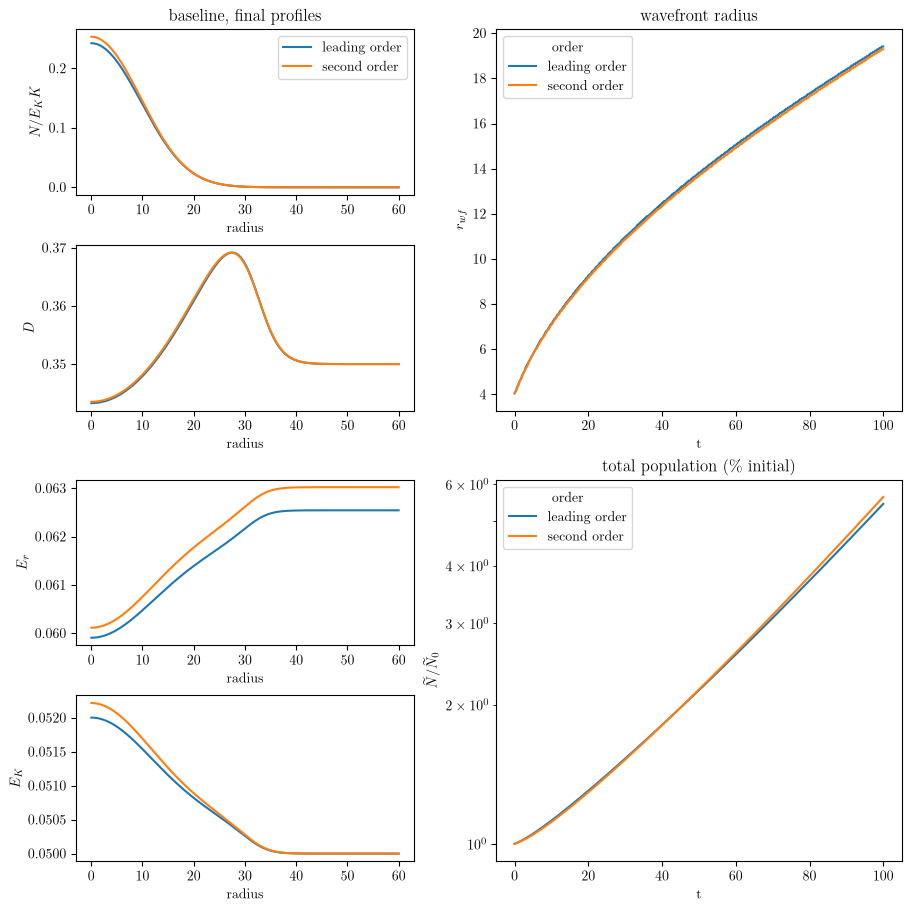

In [22]:
# Compare leading-order and second-order runs: final profiles (left), front and mass (right).
df_trait = pd.DataFrame(trait_wavefront, columns=['order', 't', 'r', 'N', 'eff_area'])
df_trait['N_init'] = config_dict['seed']['N_init']
df_trait['N_perc'] = df_trait['N'] / df_trait['N_init']
order_palette = dict(zip(orders, sns.color_palette("tab10", n_colors=len(orders))))

fig = plt.figure(figsize=(9, 9), constrained_layout=True)
gs = fig.add_gridspec(4, 2, width_ratios=[1, 1.2])
profile_panels = [
    (1, "$N/E_{K}K$"),
    (2, "$D$"),
    (3, r"$E_{r}$"),
    (4, r"$E_{K}$"),
]
for row, (col_idx, label) in enumerate(profile_panels):
    ax = fig.add_subplot(gs[row, 0])
    for profile in trait_final_profiles:
        ax.plot(r_coords, profile[col_idx], color=order_palette[profile[0]], label=profile[0])
    ax.set_xlabel("radius")
    ax.set_ylabel(label)
    if row == 0:
        ax.set_title("baseline, final profiles")
        ax.legend(loc="upper right")

ax_wavefront = fig.add_subplot(gs[:2, 1])
sns.lineplot(data=df_trait, x="t", y="r", hue="order", palette=order_palette, ax=ax_wavefront)
ax_wavefront.set_title("wavefront radius")
ax_wavefront.set_ylabel("$r_{wf}$")

ax_population = fig.add_subplot(gs[2:, 1])
sns.lineplot(data=df_trait, x="t", y="N_perc", hue="order", palette=order_palette, ax=ax_population)
ax_population.set_title(r"total population (\% initial)")
ax_population.set_ylabel(r"$\widetilde{N} / \widetilde{N}_{0}$")
ax_population.set_yscale("log")

plt.show()

# Hybrid PDE with retained construction benefit (derivation note, Section 10.6)
$E_r$ and $E_K$ stay place-borne fields with the notebook rate law $(1-E_j)(1-e^{-\bar b_j N})$. Heritable traits $z_1$, $z_2$ set the construction rates $b_r$, $b_K$, and $z_0$ sets motility as above. A producer keeps a share $\theta_j$ of its own construction, so it experiences $E_j^{\rm exp} = E_j + A_j(b_j(\chi_j)-\bar b_j)$ with $A_j = \theta_j(1-E_j)/\bar b_j$. With $\theta_j = 0$ the construction traits are neutral, and with $V_0 = 0$ the model reduces to the non-trait PDE. Applied to the "baseline" preset only; leading order and second order are compared. Requires `logistic_derivs` from the builder cell of the previous section.

In [23]:
# Hybrid right-hand sides (derivation note, Sections 10.2 and 10.6).
# Fields: N, E_r, E_k (place-borne niche fields), z0 (motility), z1 (b_r trait), z2 (b_K trait).
# D = D0*L(z0), b_r = br0*L(z1), b_K = bK0*L(z2). Escape reads the experienced niche,
# with an optional public share omega (escape_public). theta_r, theta_K are retained shares.
#   second_order=False: leading-order system
#   second_order=True : adds the O(V) terms (Dbar, bbar, Jensen term in Gbar, full <dG/dchi>)
# Uses logistic_derivs from the builder cell of the previous section.

def build_hybrid_rhs(
    *,
    r, K, a, h, m0, eps,           # ecology (eps = escape)
    D0, br0, bK0,                  # plateaus of D, b_r, b_K
    k0, k1, k2,                    # sigmoid steepness per trait axis
    V0, V1, V2,                    # standing trait variances (diagonal)
    theta_r, theta_K,              # retained share of own construction, in [0, 1]
    escape_public=0.0,             # omega in [0, 1]; 0 = escape follows the experienced niche
    N_eps=1e-6,                    # regulariser for 1/N in trait equations
    second_order=True,
):
    for name, val in (("theta_r", theta_r), ("theta_K", theta_K), ("escape_public", escape_public)):
        if not 0.0 <= val <= 1.0:
            raise ValueError(f"{name} must lie in [0, 1]")
    w = 1.0 - escape_public

    L0, L0p, L0pp, L0ppp, L0pppp, L0ppppp = logistic_derivs("z0", k0)
    L1, L1p, L1pp, L1ppp, _, _ = logistic_derivs("z1", k1)
    L2, L2p, L2pp, L2ppp, _, _ = logistic_derivs("z2", k2)

    D, Dp, Dpp, Dppp, Dpppp, Dppppp = (f"({D0}*{x})" for x in (L0, L0p, L0pp, L0ppp, L0pppp, L0ppppp))
    br, brp, brpp, brppp = (f"({br0}*{x})" for x in (L1, L1p, L1pp, L1ppp))
    bK, bKp, bKpp, bKppp = (f"({bK0}*{x})" for x in (L2, L2p, L2pp, L2ppp))

    # mean construction rates <b_j>
    if second_order:
        bbr = f"({br} + 0.5*{V1}*{brpp})"
        bbK = f"({bK} + 0.5*{V2}*{bKpp})"
    else:
        bbr, bbK = br, bK

    # ecology at the field values
    H = f"({a}/(1 + {a}*{h}*N))"
    Ebar = "(0.5*(E_r + E_k))"
    q = f"(1 + {eps}*{Ebar})"
    meff = f"({m0}/{q})"
    eta = f"({m0}*{eps}*{H}/(2*{q}**2))"                     # -0.5 m_E H
    kap = f"({m0}*{eps}**2*{H}/(2*{q}**3))"                  # 0.25 m_EE H
    lam = f"(-3*{m0}*{eps}**3*{H}/(4*{q}**4))"               # 0.125 m_EEE H
    crowd = f"(1 - N/({K}*E_k))"
    g = f"({r}*E_r*{crowd} - {meff}*{H})"

    # dG/dE_j^exp at the field values
    Gr = f"({r}*{crowd} + {w}*{eta})"
    GK = f"({r}*E_r*N/({K}*E_k**2) + {w}*{eta})"

    # retained-benefit factors A_j = theta_j (1 - E_j) / bbar_j
    Ar = f"({theta_r}*(1 - E_r)/{bbr})"
    AK = f"({theta_K}*(1 - E_k)/{bbK})"

    invN = f"(1/(N + {N_eps}))"
    gN = "gradient(N)"

    if not second_order:
        rhs_N = f"{D}*laplace(N) + N*{g}"

        def transport(zi):
            return f"{D}*(laplace({zi}) + 2*dot({gN}, gradient({zi}))*{invN})"

        sorting = f"{V0}*{Dp}*laplace(N)*{invN}"
        sel1 = f"({Ar}*{brp}*{Gr})"
        sel2 = f"({AK}*{bKp}*{GK})"
    else:
        Db = f"({D} + 0.5*{V0}*{Dpp})"
        Dbp = f"({Dp} + 0.5*{V0}*{Dppp})"
        Dbpp = f"({Dpp} + 0.5*{V0}*{Dpppp})"
        Dbppp = f"({Dppp} + 0.5*{V0}*{Dppppp})"

        # derivatives of G_j with respect to the experienced niches
        dGr_r = f"(-{w**2}*{kap})"
        d2Gr_r = f"(-{w**3}*{lam})"
        d2Gr_K = f"(-2*{r}*N/({K}*E_k**3) - {w**3}*{lam})"
        dGK_K = f"(-2*{r}*E_r*N/({K}*E_k**3) - {w**2}*{kap})"
        d2GK_K = f"(6*{r}*E_r*N/({K}*E_k**4) - {w**3}*{lam})"
        d2GK_r = f"(-{w**3}*{lam})"

        # mean fitness: only the Jensen term survives
        Gbar = (f"({g} + 0.5*({V1}*{Ar}**2*{brp}**2*{dGr_r}"
                f" + {V2}*{AK}**2*{bKp}**2*{dGK_K}))")

        # full selection terms <dG/dchi_j> to O(V)
        sel1 = (f"({Ar}*({brp}*{Gr}"
                f" + {V1}*(0.5*{brppp}*{Gr} + {Ar}*{brp}*{brpp}*{dGr_r} + 0.5*{Ar}**2*{brp}**3*{d2Gr_r})"
                f" + 0.5*{V2}*{AK}**2*{bKp}**2*{brp}*{d2Gr_K}))")
        sel2 = (f"({AK}*({bKp}*{GK}"
                f" + {V2}*(0.5*{bKppp}*{GK} + {AK}*{bKp}*{bKpp}*{dGK_K} + 0.5*{AK}**2*{bKp}**3*{d2GK_K})"
                f" + 0.5*{V1}*{Ar}**2*{brp}**2*{bKp}*{d2GK_r}))")

        rhs_N = (f"{Db}*laplace(N) + 2*{Dbp}*dot(gradient(z0), {gN})"
                 f" + N*({Dbp}*laplace(z0) + {Dbpp}*gradient_squared(z0))"
                 f" + N*{Gbar}")

        def transport(zi):
            return (f"{Db}*laplace({zi}) + 2*{Db}*dot({gN}, gradient({zi}))*{invN}"
                    f" + 2*{Dbp}*dot(gradient(z0), gradient({zi}))")

        sorting = (f"{V0}*({Dbp}*laplace(N)*{invN} + 2*{Dbpp}*dot({gN}, gradient(z0))*{invN}"
                   f" + {Dbpp}*laplace(z0) + {Dbppp}*gradient_squared(z0))")

    return {
        "N": rhs_N,
        "E_r": f"(1 - E_r)*(1 - exp(-{bbr}*N))",
        "E_k": f"(1 - E_k)*(1 - exp(-{bbK}*N))",
        "z0": f"{transport('z0')} + {sorting}",
        "z1": f"{V1}*{sel1} + {transport('z1')}",
        "z2": f"{V2}*{sel2} + {transport('z2')}",
    }

In [24]:
# Hybrid-model settings with no counterpart in config_dict. Values are placeholders for
# exploration, not calibrated estimates. PDE construction skips sympy.simplify (see below).
import contextlib
import sympy


@contextlib.contextmanager
def skip_sympy_simplify():
    """py-pde calls sympy.simplify on every RHS, which stalls on the long expressions; skip it while building the PDEs."""
    original = sympy.simplify
    sympy.simplify = lambda expr, *args, **kwargs: expr
    try:
        yield
    finally:
        sympy.simplify = original


hybrid_dict = {
    'k': (3, 3, 3),            # sigmoid steepness for z0 (motility), z1 (b_r), z2 (b_K)
    'V': (0.01, 0.01, 0.01),   # standing trait variances V0, V1, V2 (low-variance closure)
    'D_max_factor': 2.0,       # plateau D0 = D_max_factor * D, so the run starts at the preset D
    'b_max_factor': 2.0,       # plateaus b_j0 = b_max_factor * b_j, so the run starts at the preset b_j
    'theta': (0.5, 0.5),       # retained shares theta_r, theta_K; (0, 0) gives the neutral hybrid
    'escape_public': 0.0,      # omega; 0.0 means escape follows the experienced niche
    'N_eps': 1e-3,             # regulariser for 1/N in the trait equations
}
hybrid_scenario = 'baseline'
hybrid_orders = {'leading order': False, 'second order': True}


def build_hybrid_params(preset, traits):
    """Map a config_dict preset onto build_hybrid_rhs arguments."""
    k0, k1, k2 = traits['k']
    V0, V1, V2 = traits['V']
    theta_r, theta_K = traits['theta']
    return dict(
        r=preset['r'], K=preset['K'], a=preset['a'], h=preset['h'], m0=preset['m0'],
        eps=preset['escape'],
        D0=traits['D_max_factor'] * preset['D'],
        br0=traits['b_max_factor'] * preset['b_r'], bK0=traits['b_max_factor'] * preset['b_k'],
        k0=k0, k1=k1, k2=k2, V0=V0, V1=V1, V2=V2,
        theta_r=theta_r, theta_K=theta_K,
        escape_public=traits['escape_public'], N_eps=traits['N_eps'],
    )


def build_hybrid_state(config, preset, params):
    """Initial N from build_initial_N; E fields at E_r0, E_k0; uniform z so D, b_r, b_K start at the preset values."""
    u_field, r_coords = build_initial_N(config)
    grid = u_field.grid

    def z_for(value, plateau, k):
        p = value / plateau
        return np.log(p / (1 - p)) / k

    z_init = (
        z_for(preset['D'], params['D0'], params['k0']),
        z_for(preset['b_r'], params['br0'], params['k1']),
        z_for(preset['b_k'], params['bK0'], params['k2']),
    )
    Er_field = ScalarField(grid, data=np.full_like(u_field.data, preset['E_r0']), label="E_r")
    Ek_field = ScalarField(grid, data=np.full_like(u_field.data, preset['E_k0']), label="E_k")
    z_fields = [ScalarField(grid, data=np.full_like(u_field.data, z), label=f"z{i}")
                for i, z in enumerate(z_init)]
    return FieldCollection([u_field, Er_field, Ek_field] + z_fields), r_coords


def sigmoid_value(z, k, plateau):
    """plateau*L(z) on the grid (leading-order value, no variance correction)."""
    return plateau / (1 + np.exp(-k * z))


hybrid_preset = config_dict['presets'][hybrid_scenario]
hybrid_params = build_hybrid_params(hybrid_preset, hybrid_dict)
with skip_sympy_simplify():
    hybrid_pdes = {
        order_name: PDE(build_hybrid_rhs(**hybrid_params, second_order=flag), bc=config_dict['bcs'])
        for order_name, flag in hybrid_orders.items()
    }
print(hybrid_preset)
print(hybrid_params)

{'r': 0.5, 'K': 40, 'D': 0.35, 'a': 0.03, 'm0': 0.25, 'h': 0.05, 'b_r': 0.015, 'b_k': 0.015, 'escape': 0.5, 'E_r0': 0.05, 'E_k0': 0.05, 'description': 'default config'}
{'r': 0.5, 'K': 40, 'a': 0.03, 'h': 0.05, 'm0': 0.25, 'eps': 0.5, 'D0': 0.7, 'br0': 0.03, 'bK0': 0.03, 'k0': 3, 'k1': 3, 'k2': 3, 'V0': 0.01, 'V1': 0.01, 'V2': 0.01, 'theta_r': 0.5, 'theta_K': 0.5, 'escape_public': 0.0, 'N_eps': 0.001}


In [ ]:
# Run the baseline preset with the leading-order and second-order hybrid systems.
# Expect a numba compile on the first call of each system.
hybrid_wavefront = []
hybrid_final_profiles = []
for order_name, pde_system in hybrid_pdes.items():
    print(f"Running hybrid model ({order_name}) for preset: {hybrid_scenario}")
    state, r_coords = build_hybrid_state(config_dict, hybrid_preset, hybrid_params)
    storage = MemoryStorage()
    pde_system.solve(
        state, 
        t_range=config_dict['integration']['t_max'], 
        dt=config_dict['integration']['dt'],
                     tracker=['progress',storage.tracker(config_dict['analysis']['tracker_time'])], adaptive=True, backend='numba')
    for t_idx, time in enumerate(storage.times):
        curr_u = storage[t_idx][0].data
        idx = compute_wavefront_idx(config_dict['analysis'], curr_u, r_coords)
        hybrid_wavefront.append((order_name, time, r_coords[idx], rolling_area(curr_u, r_coords)[-1],
                                 compute_participation_area(storage[t_idx][0])))
    final = storage[-1]
    final_Er = final[1].data
    final_Ek = final[2].data
    final_N = final[0].data / (hybrid_params['K'] * final_Ek)
    final_D = sigmoid_value(final[3].data, hybrid_params['k0'], hybrid_params['D0'])
    final_br = sigmoid_value(final[4].data, hybrid_params['k1'], hybrid_params['br0'])
    final_bK = sigmoid_value(final[5].data, hybrid_params['k2'], hybrid_params['bK0'])
    hybrid_final_profiles.append((order_name, final_N, final_D, final_Er, final_Ek, final_br, final_bK))

Running hybrid model (leading order) for preset: baseline








100%|██████████| 1.0/1.0 [00:03<00:00,  3.22s/it]


Running hybrid model (second order) for preset: baseline




Initializing:   0%|          | 0/100.0 [01:06<?, ?it/s]


KeyboardInterrupt: 

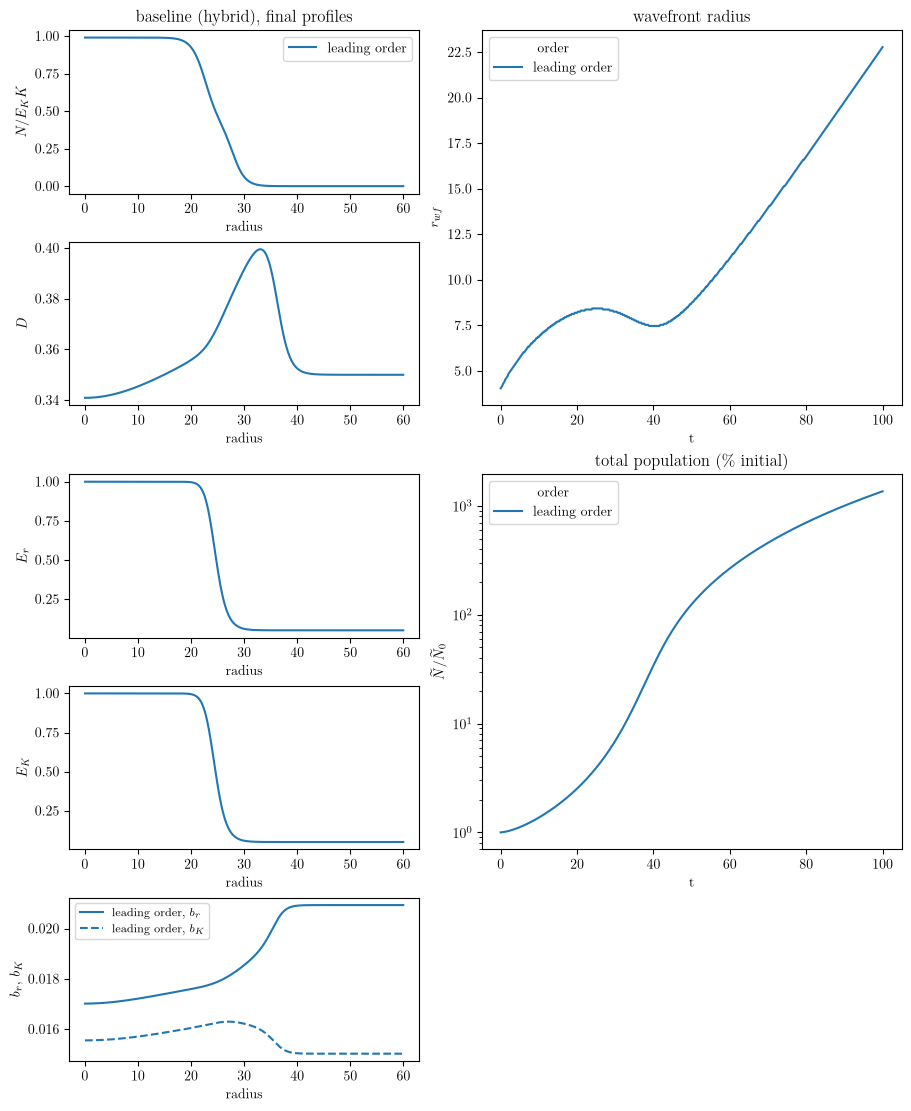

In [26]:
# Compare leading-order and second-order hybrid runs: final profiles (left), front and mass (right).
df_hybrid = pd.DataFrame(hybrid_wavefront, columns=['order', 't', 'r', 'N', 'eff_area'])
df_hybrid['N_init'] = config_dict['seed']['N_init']
df_hybrid['N_perc'] = df_hybrid['N'] / df_hybrid['N_init']
hybrid_palette = dict(zip(hybrid_orders, sns.color_palette("tab10", n_colors=len(hybrid_orders))))

fig = plt.figure(figsize=(9, 11), constrained_layout=True)
gs = fig.add_gridspec(5, 2, width_ratios=[1, 1.2])
profile_panels = [
    ((1,), ("$N/E_{K}K$",)),
    ((2,), ("$D$",)),
    ((3,), (r"$E_{r}$",)),
    ((4,), (r"$E_{K}$",)),
    ((5, 6), (r"$b_{r}$", r"$b_{K}$")),
]
for row, (col_idxs, labels) in enumerate(profile_panels):
    ax = fig.add_subplot(gs[row, 0])
    for profile in hybrid_final_profiles:
        for col_idx, label, style in zip(col_idxs, labels, ("-", "--")):
            ax.plot(r_coords, profile[col_idx], color=hybrid_palette[profile[0]], linestyle=style,
                    label=f"{profile[0]}, {label}" if len(col_idxs) > 1 else profile[0])
    ax.set_xlabel("radius")
    ax.set_ylabel(", ".join(labels))
    if row == 0:
        ax.set_title("baseline (hybrid), final profiles")
        ax.legend(loc="upper right")
    if len(col_idxs) > 1:
        ax.legend(loc="best", fontsize="small")

ax_wavefront = fig.add_subplot(gs[:2, 1])
sns.lineplot(data=df_hybrid, x="t", y="r", hue="order", palette=hybrid_palette, ax=ax_wavefront)
ax_wavefront.set_title("wavefront radius")
ax_wavefront.set_ylabel("$r_{wf}$")

ax_population = fig.add_subplot(gs[2:4, 1])
sns.lineplot(data=df_hybrid, x="t", y="N_perc", hue="order", palette=hybrid_palette, ax=ax_population)
ax_population.set_title(r"total population (\% initial)")
ax_population.set_ylabel(r"$\widetilde{N} / \widetilde{N}_{0}$")
ax_population.set_yscale("log")

plt.show()